# London Transport Reliabilty - Data Exploration and Quality Assessment

In [45]:
import pandas as pd
from pathlib import Path

In [46]:
from pathlib import Path

project_folder = Path.cwd().resolve().parent

data_path = (
    project_folder
    / "data"
    / "raw"
    / "trains-service-status-messages.csv"
)

print("CSV exists:", data_path.exists())

# Finds the project folder by moving up from the notebooks folder.
# Builds a relative path to the original TfL dataset.
# Avoids using a personal Mac Desktop path.
# Checks that the CSV file can be found.

CSV exists: True


In [47]:
df = pd.read_csv(data_path, nrows=5)

In [48]:
df.head()

,Line,Start Date/Time,End Date/Time,Service Status,Status Message Details
0,Northern,01/04/2022 04:25:01,01/04/2022 04:27:46,Part Closure,No service between Moorgate and Kennington due...
1,Northern,01/04/2022 04:27:46,01/04/2022 11:01:45,Part Closure,No service between Moorgate and Kennington due...
2,Bakerloo,01/04/2022 05:19:49,01/04/2022 05:28:20,Part Suspended,No service between Queens Park and Harrow & We...
3,Bakerloo,01/04/2022 05:28:20,01/04/2022 05:41:53,Part Suspended,No service between Queens Park and Harrow & We...
4,Bakerloo,01/04/2022 05:41:53,01/04/2022 05:42:00,Part Suspended,No service between Queens Park and Harrow & We...


In [49]:
print("Sample shape:", df.shape)
print("Columns:", df.columns.tolist())

Sample shape: (5, 5)
Columns: ['Line', 'Start Date/Time', 'End Date/Time', 'Service Status', 'Status Message Details']


In [50]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   Line                    5 non-null      str  
 1   Start Date/Time         5 non-null      str  
 2   End Date/Time           5 non-null      str  
 3   Service Status          5 non-null      str  
 4   Status Message Details  5 non-null      str  
dtypes: str(5)
memory usage: 332.0 bytes


In [51]:
sample_df = pd.read_csv(data_path, nrows=1000)

print(sample_df["Service Status"].value_counts(dropna=False))

Service Status
Minor Delays       313
Severe Delays      206
Service Closed     176
Part Suspended     147
Part Closure       142
Suspended           10
Planned Closure      6
Name: count, dtype: int64


In [52]:
sample_df.dtypes

Line                      str
Start Date/Time           str
End Date/Time             str
Service Status            str
Status Message Details    str
dtype: object

In [53]:
date_format = "%d/%m/%Y %H:%M:%S"

sample_df["Start Date/Time"] = pd.to_datetime(
    sample_df["Start Date/Time"],
    format=date_format,
    errors="coerce"
)

sample_df["End Date/Time"] = pd.to_datetime(
    sample_df["End Date/Time"],
    format=date_format,
    errors="coerce"
)

In [54]:
sample_df["duration_minutes"] = (
    sample_df["End Date/Time"] - sample_df["Start Date/Time"]
).dt.total_seconds() / 60

sample_df[
    ["Line", "Service Status", "duration_minutes"]
].head(10)

,Line,Service Status,duration_minutes
0,Northern,Part Closure,2.750000
1,Northern,Part Closure,393.983333
2,Bakerloo,Part Suspended,8.516667
3,Bakerloo,Part Suspended,13.550000
4,Bakerloo,Part Suspended,0.116667
5,Bakerloo,Part Suspended,20.433333
6,C&H,Minor Delays,13.616667
7,C&H,Minor Delays,0.483333
8,C&H,Minor Delays,50.283333
9,District,Minor Delays,1.700000


In [55]:
print("Missing start dates:", sample_df["Start Date/Time"].isna().sum())
print("Missing end dates:", sample_df["End Date/Time"].isna().sum())
print("Negative durations:", (sample_df["duration_minutes"] < 0).sum())
print("Zero durations:", (sample_df["duration_minutes"] == 0).sum())

Missing start dates: 0
Missing end dates: 0
Negative durations: 0
Zero durations: 0


In [56]:
sorted_df = sample_df.sort_values(
    by=["Line", "Start Date/Time"]
).copy()

sorted_df.head()

,Line,Start Date/Time,End Date/Time,Service Status,Status Message Details,duration_minutes
2,Bakerloo,2022-04-01 05:19:49,2022-04-01 05:28:20,Part Suspended,No service between Queens Park and Harrow & We...,8.516667
3,Bakerloo,2022-04-01 05:28:20,2022-04-01 05:41:53,Part Suspended,No service between Queens Park and Harrow & We...,13.550000
4,Bakerloo,2022-04-01 05:41:53,2022-04-01 05:42:00,Part Suspended,No service between Queens Park and Harrow & We...,0.116667
5,Bakerloo,2022-04-01 05:42:00,2022-04-01 06:02:26,Part Suspended,No service between Queens Park and Harrow & We...,20.433333
45,Bakerloo,2022-04-02 01:07:54,2022-04-02 04:14:26,Service Closed,Train service will resume later this morning.,186.533333


In [57]:
sorted_df["previous_end"] = (
    sorted_df.groupby("Line")["End Date/Time"].shift(1)
)

sorted_df["previous_status"] = (
    sorted_df.groupby("Line")["Service Status"].shift(1)
)

In [58]:
sorted_df["continues_previous"] = (
    (sorted_df["Start Date/Time"] == sorted_df["previous_end"])
    & (sorted_df["Service Status"] == sorted_df["previous_status"])
)

In [59]:
print(
    "Consecutive same-status records:",
    sorted_df["continues_previous"].sum()
)

print(
    "Percentage of sample:",
    round(sorted_df["continues_previous"].mean() * 100, 2),
    "%"
)

Consecutive same-status records: 190
Percentage of sample: 19.0 %


190 out of 1000 (19%) meet the consecutive same-status condition, this suggests that TfL sometimes divides an ongoing service condition into multiple records. However, this also doesn't prove that 19% of the disruptions are duplicates, these could be legitimate updates with different explanations or affected locations. 

In [60]:
matches = sorted_df[
    sorted_df["continues_previous"]
]

matches[
    [
        "Line",
        "Start Date/Time",
        "End Date/Time",
        "Service Status",
        "Status Message Details"
    ]
].head(10)

,Line,Start Date/Time,End Date/Time,Service Status,Status Message Details
3,Bakerloo,2022-04-01 05:28:20,2022-04-01 05:41:53,Part Suspended,No service between Queens Park and Harrow & We...
4,Bakerloo,2022-04-01 05:41:53,2022-04-01 05:42:00,Part Suspended,No service between Queens Park and Harrow & We...
5,Bakerloo,2022-04-01 05:42:00,2022-04-01 06:02:26,Part Suspended,No service between Queens Park and Harrow & We...
180,Bakerloo,2022-04-04 10:16:24,2022-04-04 10:17:25,Part Suspended,No service between Queen's Park and Harrow & W...
181,Bakerloo,2022-04-04 10:17:25,2022-04-04 10:23:40,Part Suspended,No service between Queen's Park and Harrow & W...
182,Bakerloo,2022-04-04 10:23:40,2022-04-04 10:54:08,Part Suspended,No service between Queen's Park and Harrow & W...
183,Bakerloo,2022-04-04 10:54:08,2022-04-04 11:03:14,Part Suspended,No service between Queen's Park and Harrow & W...
187,Bakerloo,2022-04-04 11:16:28,2022-04-04 12:50:22,Severe Delays,Severe delays due to an earlier obstruction on...
615,Bakerloo,2022-04-10 17:10:10,2022-04-10 17:17:11,Part Closure,No service between Queen's Park and Harrow & W...
616,Bakerloo,2022-04-10 17:17:11,2022-04-11 01:43:25,Part Closure,No service between Queen's Park and Harrow & W...


In the first 1,000 TfL service-status records, 190 (19%) begin exactly when the previous record for the same line ended and retain the same service status. This indicates that counting status records may overstate the number of distinct distruption periods. Further investigation of message details is needed before grouping records.

In [61]:
sorted_df["previous_message"] = (
    sorted_df.groupby("Line")["Status Message Details"].shift(1)
)

sorted_df["same_message"] = (
    sorted_df["Status Message Details"]
    == sorted_df["previous_message"]
)

matches = sorted_df[
    sorted_df["continues_previous"]
].copy()

print(
    "Consecutive records with identical messages:",
    matches["same_message"].sum()
)

print(
    "Consecutive records with different messages:",
    (~matches["same_message"]).sum()
)

Consecutive records with identical messages: 10
Consecutive records with different messages: 180


In [62]:
sorted_df["overlaps_previous"] = (
    sorted_df["Start Date/Time"]
    < sorted_df["previous_end"]
)

print(
    "Records overlapping the previous record:",
    sorted_df["overlaps_previous"].sum()
)

Records overlapping the previous record: 356


In [63]:
sorted_df.loc[
    sorted_df["overlaps_previous"],
    [
        "Line",
        "Start Date/Time",
        "End Date/Time",
        "Service Status",
        "previous_end"
    ]
].head(10)

,Line,Start Date/Time,End Date/Time,Service Status,previous_end
184,Bakerloo,2022-04-04 10:54:08,2022-04-04 11:03:14,Minor Delays,2022-04-04 11:03:14
186,Bakerloo,2022-04-04 11:03:14,2022-04-04 11:16:28,Severe Delays,2022-04-04 11:16:28
614,Bakerloo,2022-04-10 16:32:54,2022-04-10 17:10:10,Part Closure,2022-04-10 17:10:09
46,C&H,2022-04-02 01:08:07,2022-04-02 04:14:58,Service Closed,2022-04-02 01:08:39
48,C&H,2022-04-02 01:08:39,2022-04-02 04:15:15,Service Closed,2022-04-02 04:14:58
75,C&H,2022-04-02 09:35:51,2022-04-03 01:16:33,Minor Delays,2022-04-02 11:27:22
76,C&H,2022-04-02 11:27:22,2022-04-02 11:27:38,Minor Delays,2022-04-03 01:16:33
77,C&H,2022-04-02 11:27:22,2022-04-02 12:27:37,Severe Delays,2022-04-02 11:27:38
78,C&H,2022-04-02 11:27:38,2022-04-02 12:27:37,Minor Delays,2022-04-02 12:27:37
90,C&H,2022-04-03 01:16:33,2022-04-03 05:23:15,Service Closed,2022-04-03 05:22:57


In [64]:
original_columns = [
    "Line",
    "Start Date/Time",
    "End Date/Time",
    "Service Status",
    "Status Message Details"
]

print(
    "Exact duplicate records:",
    sample_df.duplicated(subset=original_columns).sum()
)

Exact duplicate records: 129


In [65]:
overlap_statuses = sorted_df.loc[
    sorted_df["overlaps_previous"],
    ["Service Status", "previous_status"]
]

print(
    "Overlaps with same status:",
    (
        overlap_statuses["Service Status"]
        == overlap_statuses["previous_status"]
    ).sum()
)

print(
    "Overlaps with different status:",
    (
        overlap_statuses["Service Status"]
        != overlap_statuses["previous_status"]
    ).sum()
)

Overlaps with same status: 175
Overlaps with different status: 181


## Data Quality Finding: Overlapping service-status intervals
In the intial sample, 356 records overlap the preceding record for the same line, based on our first-pass check. The naive summation of interval durations could double-count time, therfore, with furhter interval-handling method will be needed. In addition, we cannot reliably calculate distruption frequency or total disruption duration by simply country rows or summing their durations.


In [66]:
duplicate_rows = sample_df[
    sample_df.duplicated(
        subset=original_columns,
        keep=False
    )
].sort_values(
    ["Line", "Start Date/Time"]
)

duplicate_rows[original_columns].head(10)

,Line,Start Date/Time,End Date/Time,Service Status,Status Message Details
480,C&H,2022-04-09 06:58:53,2022-04-09 07:04:16,Part Suspended,No service anticlockwise and no service betwee...
481,C&H,2022-04-09 06:58:53,2022-04-09 07:04:16,Part Suspended,No service anticlockwise and no service betwee...
485,C&H,2022-04-09 07:04:16,2022-04-09 07:15:25,Part Suspended,No service anticlockwise and no service betwee...
486,C&H,2022-04-09 07:04:16,2022-04-09 07:15:25,Part Suspended,No service anticlockwise and no service betwee...
458,Central,2022-04-09 01:55:20,2022-04-09 02:32:32,Part Suspended,"No service West Ruislip to North Acton, Leyton..."
459,Central,2022-04-09 01:55:20,2022-04-09 02:32:32,Part Suspended,"No service West Ruislip to North Acton, Leyton..."
460,Central,2022-04-09 01:55:20,2022-04-09 02:32:32,Part Suspended,"No service West Ruislip to North Acton, Leyton..."
461,Central,2022-04-09 01:55:20,2022-04-09 02:32:32,Part Suspended,"No service West Ruislip to North Acton, Leyton..."
466,Central,2022-04-09 02:32:32,2022-04-09 06:08:41,Part Suspended,"No service West Ruislip to North Acton, Leyton..."
467,Central,2022-04-09 02:32:32,2022-04-09 06:08:41,Part Suspended,"No service West Ruislip to North Acton, Leyton..."


In [67]:
unique_df = sample_df.drop_duplicates(
    subset=original_columns
).copy()

print("Original sample rows:", len(sample_df))
print("Unique sample rows:", len(unique_df))
print("Rows removed:", len(sample_df) - len(unique_df))

Original sample rows: 1000
Unique sample rows: 871
Rows removed: 129


### Initial data-quality assessment:
The first 1,000 TfL records contain 129 exact duplicate rows. An initial overlap check also identified 356 records overlapping the preceding record for the same line, including 175 with matching statuses and 181 with different statuses. The findings indicate that record counts and summed durations should not be interpreted directly as incident counts or total disrupted time.

In [68]:
unique_sorted = unique_df.sort_values(
    by=["Line", "Start Date/Time", "End Date/Time"]
).copy()

In [69]:
unique_sorted["previous_end"] = (
    unique_sorted.groupby("Line")["End Date/Time"].shift(1)
)

unique_sorted["overlaps_previous"] = (
    unique_sorted["Start Date/Time"]
    < unique_sorted["previous_end"]
)

print(
    "Overlaps after deduplication:",
    unique_sorted["overlaps_previous"].sum()
)

Overlaps after deduplication: 227


In [70]:
unique_sorted["latest_previous_end"] = (
    unique_sorted.groupby("Line")["End Date/Time"]
    .transform(lambda s: s.cummax().shift(1))
)

unique_sorted["overlaps_any_previous"] = (
    unique_sorted["Start Date/Time"]
    < unique_sorted["latest_previous_end"]
)

print(
    "Records overlapping any earlier interval:",
    unique_sorted["overlaps_any_previous"].sum()
)

Records overlapping any earlier interval: 248


In [71]:
with open(data_path, "r", encoding="utf-8-sig") as file:
    total_rows = sum(1 for _ in file) - 1

print("Total data rows:", total_rows)

Total data rows: 120043


In [72]:
full_df = pd.read_csv(data_path)

print("Total records:", len(full_df))
print("Total columns:", len(full_df.columns))

Total records: 118595
Total columns: 5


In [73]:
full_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 118595 entries, 0 to 118594
Data columns (total 5 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   Line                    118595 non-null  str  
 1   Start Date/Time         118595 non-null  str  
 2   End Date/Time           118595 non-null  str  
 3   Service Status          118595 non-null  str  
 4   Status Message Details  115128 non-null  str  
dtypes: str(5)
memory usage: 4.5 MB


In [74]:
full_df.isna().sum()

Line                         0
Start Date/Time              0
End Date/Time                0
Service Status               0
Status Message Details    3467
dtype: int64

In [75]:
full_df["Start Date/Time"] = pd.to_datetime(
    full_df["Start Date/Time"],
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce"
)

full_df["End Date/Time"] = pd.to_datetime(
    full_df["End Date/Time"],
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce"
)

print("Earliest start:", full_df["Start Date/Time"].min())
print("Latest end:", full_df["End Date/Time"].max())

print("Invalid start dates:", full_df["Start Date/Time"].isna().sum())
print("Invalid end dates:", full_df["End Date/Time"].isna().sum())

Earliest start: 2022-04-01 04:25:01
Latest end: 2026-09-21 00:45:44
Invalid start dates: 0
Invalid end dates: 0


### TfL Dataset - Full Inspection

- Actual CSV Records: 118,595 
- Columns: 5
- Approximate Data Coverage: 4.5 years
- Missing Status messages: 3,467

Earliest Start:             1 April 2022

Latest End:                 21 September 2026

In [76]:
print("Number of lines:", full_df["Line"].nunique())

print("\nLine names:")
print(sorted(full_df["Line"].unique()))

Number of lines: 10

Line names:
['Bakerloo', 'C&H', 'Central', 'District', 'Jubilee', 'Metropolitan', 'Northern', 'Piccadilly', 'Victoria', 'Waterloo & City']


In [77]:
full_df["Service Status"].value_counts(dropna=False)

Service Status
Minor Delays       40556
Severe Delays      29953
Part Suspended     20747
Service Closed     17364
Part Closure        6547
Planned Closure     1933
Suspended           1331
Special Service      140
Good Service          19
Reduced Service        5
Name: count, dtype: int64

In [78]:
original_columns = [
    "Line",
    "Start Date/Time",
    "End Date/Time",
    "Service Status",
    "Status Message Details"
]

print(
    "Exact duplicate records:",
    full_df.duplicated(subset=original_columns).sum()
)

Exact duplicate records: 13995


In [79]:
print(full_df[["Start Date/Time", "End Date/Time"]].dtypes)

Start Date/Time    datetime64[us]
End Date/Time      datetime64[us]
dtype: object


In [80]:
date_format = "%d/%m/%Y %H:%M:%S"

full_df["Start Date/Time"] = pd.to_datetime(
    full_df["Start Date/Time"],
    format=date_format,
    errors="coerce"
)

full_df["End Date/Time"] = pd.to_datetime(
    full_df["End Date/Time"],
    format=date_format,
    errors="coerce"
)

print(full_df[["Start Date/Time", "End Date/Time"]].dtypes)

Start Date/Time    datetime64[us]
End Date/Time      datetime64[us]
dtype: object


In [81]:
full_df["duration_minutes"] = (
    full_df["End Date/Time"] - full_df["Start Date/Time"]
).dt.total_seconds() / 60

print("Negative durations:", (full_df["duration_minutes"] < 0).sum())
print("Zero durations:", (full_df["duration_minutes"] == 0).sum())
print("Missing durations:", full_df["duration_minutes"].isna().sum())

Negative durations: 15
Zero durations: 43
Missing durations: 0


In [82]:
negative_df = full_df.loc[
    full_df["duration_minutes"] < 0,
    [
        "Line",
        "Start Date/Time",
        "End Date/Time",
        "Service Status",
        "duration_minutes"
    ]
].copy()

negative_df.sort_values("duration_minutes")

,Line,Start Date/Time,End Date/Time,Service Status,duration_minutes
98421,Jubilee,2026-03-06 13:04:47,2025-11-20 22:40:38,Severe Delays,-152064.150000
94092,Central,2026-01-12 17:36:31,2025-11-20 21:55:51,Severe Delays,-76060.666667
98422,Central,2026-03-06 13:09:25,2026-01-12 17:36:31,Minor Delays,-76052.900000
94093,Metropolitan,2026-01-12 17:50:57,2025-11-20 22:23:23,Part Suspended,-76047.566667
94094,Metropolitan,2026-01-12 17:50:57,2025-11-20 22:23:23,Severe Delays,-76047.566667
98420,Metropolitan,2026-03-06 12:59:20,2026-01-12 17:50:56,Severe Delays,-76028.400000
64294,Metropolitan,2025-01-01 08:58:26,2024-12-28 04:20:10,Service Closed,-6038.266667
64293,C&H,2025-01-01 08:58:15,2024-12-28 04:20:03,Service Closed,-6038.200000
64292,District,2025-01-01 08:56:12,2024-12-28 04:19:42,Service Closed,-6036.500000
64291,C&H,2025-01-01 08:55:48,2024-12-28 04:19:39,Service Closed,-6036.150000


In [83]:
negative_df["duration_minutes"].describe()

count        15.000000
mean     -38208.110000
std       46584.348105
min     -152064.150000
25%      -76047.566667
50%       -6038.200000
75%       -6034.341667
max          -2.250000
Name: duration_minutes, dtype: float64

In [84]:
zero_df = full_df.loc[
    full_df["duration_minutes"] == 0,
    [
        "Line",
        "Start Date/Time",
        "End Date/Time",
        "Service Status"
    ]
]

zero_df.head(10)

,Line,Start Date/Time,End Date/Time,Service Status
73673,Victoria,2025-05-20 07:30:21,2025-05-20 07:30:21,Minor Delays
73681,Metropolitan,2025-05-20 08:19:17,2025-05-20 08:19:17,Minor Delays
73684,Waterloo & City,2025-05-20 08:40:28,2025-05-20 08:40:28,Minor Delays
74237,District,2025-05-26 13:56:06,2025-05-26 13:56:06,Severe Delays
74351,Central,2025-05-27 16:59:28,2025-05-27 16:59:28,Part Suspended
74368,Metropolitan,2025-05-27 19:20:10,2025-05-27 19:20:10,Minor Delays
74647,Waterloo & City,2025-05-31 00:24:48,2025-05-31 00:24:48,Service Closed
75352,Central,2025-06-09 08:36:35,2025-06-09 08:36:35,Minor Delays
75353,Central,2025-06-09 08:36:35,2025-06-09 08:36:35,Severe Delays
76080,Victoria,2025-06-16 21:24:28,2025-06-16 21:24:28,Minor Delays


### Duration Quality Classification

Classify each service-status interval according to whether its duration is positive, zero, negative, or missing.

Preserve the original records for auditing.

In [85]:
full_df["duration_quality"] = "valid"

full_df.loc[
    full_df["duration_minutes"] == 0,
    "duration_quality"
] = "zero_duration"

full_df.loc[
    full_df["duration_minutes"] < 0,
    "duration_quality"
] = "negative_duration"

full_df.loc[
    full_df["duration_minutes"].isna(),
    "duration_quality"
] = "missing_duration"

full_df["duration_quality"].value_counts()

duration_quality
valid                118537
zero_duration            43
negative_duration        15
Name: count, dtype: int64

### Zero-Duration Recors by Service Status

Investigate whether zero-duration records are concentratred in particular service-status categories.

In [86]:
zero_status_counts = (
    full_df.loc[
        full_df["duration_quality"] == "zero_duration",
        "Service Status"
    ]
    .value_counts()
)

zero_status_counts

Service Status
Minor Delays      15
Severe Delays      9
Part Suspended     7
Part Closure       6
Service Closed     5
Suspended          1
Name: count, dtype: int64

**Observation:** The dataset contains 43 zero-duration records across six service-status categories. Minor Delays account for the largest number (15). 
 
 These records have identical start and end timestamps and therefore contribute no measurable elapsed time.

 Their underlying cause is unknown, so they will be retained for auditing but excluded from duration-based calculations.

### Duplicate Records by Service Status

Investigate which service-status categories contain exact duplicate records before deciding how to handle them.

In [87]:
original_columns = [
    "Line",
    "Start Date/Time",
    "End Date/Time",
    "Service Status",
    "Status Message Details"
]

duplicate_mask = full_df.duplicated(
    subset=original_columns,
    keep="first"
)

duplicate_status_counts = (
    full_df.loc[duplicate_mask, "Service Status"]
    .value_counts()
)

print("Total duplicate records:", duplicate_mask.sum())

duplicate_status_counts

Total duplicate records: 13995


Service Status
Minor Delays       5426
Severe Delays      3893
Part Suspended     2929
Part Closure       1673
Special Service      74
Name: count, dtype: int64

### Removing Exact Duplicate Records

Create a seperate analysis-ready DataFrame by removing repeated copies of records that are identical across all five original dataset columns.

Preserve the origina dataset for auditing.

In [88]:
clean_df = full_df.drop_duplicates(
    subset=original_columns,
    keep="first"
).copy()

print("Original records:", len(full_df))
print("Recirds after deduplication:", len(clean_df))
print("Records removed:", len(full_df) - len(clean_df))

# This duplicates copies, not overlapping but different intervals.

Original records: 118595
Recirds after deduplication: 104600
Records removed: 13995


In [89]:
remaining_duplicates = clean_df.duplicated(
    subset=original_columns

).sum()

print("Remaining exact duplicates:", remaining_duplicates)

Remaining exact duplicates: 0


### Overlapping Service-Status Intervals

Identify records whose time intervals overlap with earlier records on the same transport line.

Overlappung intervals may represent simultaneous service conditions or repeated status updates.

In [90]:
overlap_df = clean_df.sort_values(
    by=["Line", "Start Date/Time", "End Date/Time"]
).copy()

overlap_df["latest_previous_end"] = (
    overlap_df.groupby("Line")["End Date/Time"]
    .transform(lambda s: s.cummax().shift(1))
)

overlap_df["overlaps_previous"] = (
    overlap_df["Start Date/Time"]
    < overlap_df["latest_previous_end"]
)

print(
    "Records overlapping an earlier interval:",
    overlap_df["overlaps_previous"].sum()
)

print(
    "Percentage of deduplicated records:",
    round(overlap_df["overlaps_previous"].mean()* 100, 2),
    "%"
)
# Sorts records chronologically within each transport line.
# cummax() tracks the latest end time encountered on that line.
# shift(1) excludes the current record from its own comparison.
# A record is flagged if it starts before an earlier interval has ended.
# This counts overlapping records, not distinct incidents or overlapping minutes.
# No overlapping records are removed or modified.


Records overlapping an earlier interval: 27783
Percentage of deduplicated records: 26.56 %


**Observation** After removing exact duplicates, 27,783 of 104,600 records (26.56%) start before an earlier interval in the same transport line has ended. 

This suggests substantial overlap in the recorded service-status intervals.

The percentage represents overlapping records, not the proportion of time the network was distrupted.

Overlapping intervals must be handled before summing durations to avoid double-counting.

### Overlapping Records by Service Status

Examine the distribution of service statuses among records that overlap an earlier interval on the same line.

In [91]:
overlap_status_counts = (
    overlap_df.loc[
        overlap_df["overlaps_previous"],
        "Service Status"
    ]
    .value_counts()
)

print(overlap_status_counts)

print("\nTotal overlapping records:",
overlap_status_counts.sum())

Service Status
Minor Delays       10803
Severe Delays       9664
Part Suspended      3401
Service Closed      2236
Part Closure        1264
Suspended            349
Planned Closure       45
Special Service       19
Good Service           2
Name: count, dtype: int64

Total overlapping records: 27783


### Final Data Quality Checks

Befoer exporting the cleaned dataset, examine invalid durations and overlapping service status intervals.

The aim is to preserve useful records while preventing misleading duratiin calculations.

In [92]:
print("Deduplicated records:", len(clean_df))

print("\nDuration quality:")
print(clean_df["duration_quality"].value_counts())

print("\nOverlapping records by duration quality:")
print(
    overlap_df.loc[
        overlap_df["overlaps_previous"],
        "duration_quality"
    ].value_counts()
)

# Reports the number of records remaining after exact deduplication.
# Shows how many records have valid, zero or negative durations.
# Checks whether any records flagged as overlapping also have invalid durations.
# Helps us decide which records can be used for duration-based analysis.

Deduplicated records: 104600

Duration quality:
duration_quality
valid                104544
zero_duration            41
negative_duration        15
Name: count, dtype: int64

Overlapping records by duration quality:
duration_quality
valid                27774
negative_duration        7
zero_duration            2
Name: count, dtype: int64


In [93]:
columns_to_show = [
    "Line",
    "Start Date/Time",
    "End Date/Time",
    "Service Status",
    "duration_minutes",
    "latest_previous_end"
]

overlap_examples = overlap_df.loc[
    (overlap_df["overlaps_previous"])
    & (overlap_df["duration_quality"] == "valid"),
    columns_to_show
].head(5)

display(overlap_examples)

#Selects five overlapping records with positive durations, displays their line, start time, end time, service status.
#Allows fot inspection of real overlaps before cleaning rules.
# Does not modify nor remove any records

,Line,Start Date/Time,End Date/Time,Service Status,duration_minutes,latest_previous_end
184,Bakerloo,2022-04-04 10:54:08,2022-04-04 11:03:14,Minor Delays,9.100000,2022-04-04 11:03:14
186,Bakerloo,2022-04-04 11:03:14,2022-04-04 11:16:28,Severe Delays,13.233333,2022-04-04 11:16:28
614,Bakerloo,2022-04-10 16:32:54,2022-04-10 17:10:10,Part Closure,37.266667,2022-04-10 17:10:09
1468,Bakerloo,2022-04-23 11:13:19,2022-04-23 14:19:10,Minor Delays,185.850000,2022-04-23 14:19:08
1493,Bakerloo,2022-04-23 20:04:12,2022-04-23 20:11:12,Minor Delays,7.000000,2022-04-23 20:11:12


### Cleaning Decision: Duration and Overlap

- Removes exact duplicate records from the analysis dataset.
- Retains records with zero or negative duratuins for data quality reporting, but exclude them from duration-based calculations.
- Preserves overlapping records becayse they may represent legitmate simultaneous service status or updates.
- Do not sum overlapping interval durations as though they represent independant disruption periods.
- Use the cleaned records primarily to analyse patterns in recorded service statuses across lines and time periods.

### Export the Cleaned Dataset

Save the deduplicated dataset, including duration-quality information for further analysis using SQL.

The original raw dataset will remained unchanged.

In [94]:
from pathlib import Path

processed_folder = data_path.parent.parent / "processed"
processed_folder.mkdir(parents=True, exist_ok=True)

output_path = processed_folder / "tfl_service_status_cleaned.csv"

clean_df.to_csv(output_path, index=False)

print("Cleaned dataset saved to:")
print(output_path)
print("Rows exported:", len(clean_df))

# Exports the deduplicated dataset as a CSV without a Pandas index.
# Preserves duration-quality labels and the original status information.
# Does not change or overwrite the raw CSV.


Cleaned dataset saved to:
/Users/harirazannah/Desktop/london-transport-reliability/data/processed/tfl_service_status_cleaned.csv
Rows exported: 104600


In [95]:
from pathlib import Path
processed_path = (
    data_path.parent.parent
    / "processed"
    / "tfl_service_status_cleaned.csv"
)

print("CSV exists:", processed_path.exists())
print("CSV location`:", processed_path)

CSV exists: True
CSV location`: /Users/harirazannah/Desktop/london-transport-reliability/data/processed/tfl_service_status_cleaned.csv


In [96]:
import pandas as pd
import sqlite3

database_path = data_path.parent.parent / "tfl_reliability.db"

sql_df = pd.read_csv(processed_path)

with sqlite3.connect(database_path) as connection:
    sql_df.to_sql(
        "service_status",
        connection,
        if_exists="replace",
        index=False
    )

print("SQLite database created:", database_path)
print("Rows imported:", len(sql_df))

# Reads the exported, deduplicated CSV into Pandas.
# Creates a SQLite database inside the project folder.
# Imports the records into a table called service_status.
# Replaces the table if it already exists, avoiding duplicate imports.
# Keeps the CSV and raw dataset unchanged.

SQLite database created: /Users/harirazannah/Desktop/london-transport-reliability/data/tfl_reliability.db
Rows imported: 104600


## SQL Analysis

### Query 1: Service-Status Records by Transport Line

Identify which transport lines have the highest number of recorded service-status entries in the cleaned dataset

In [97]:
query_1 = """
SELECT
    Line, 
    COUNT (*) AS total_records
FROM service_status
GROUP BY Line
ORDER BY total_records DESC;
"""

with sqlite3.connect(database_path) as connection:
    line_counts = pd.read_sql_query(query_1, connection)

display(line_counts)

,Line,total_records
0,District,17703
1,Piccadilly,14925
2,C&H,14171
3,Metropolitan,13523
4,Central,10142
5,Northern,9095
6,Bakerloo,8594
7,Jubilee,7523
8,Victoria,4569
9,Waterloo & City,4355


### Query 2: Severe Delay Records by Line

Count the number of records classified as Severe Delays for each transport line.

In [98]:
query_2 = '''
SELECT
    Line, 
    COUNT(*) AS severe_delay_records
FROM service_status
WHERE "Service Status" = 'Severe Delays'
GROUP BY Line
ORDER BY severe_delay_records DESC;
'''

with sqlite3.connect(database_path) as connection:
    severe_delay_counts = pd.read_sql_query(query_2, connection)

display(severe_delay_counts)

,Line,severe_delay_records
0,District,5319
1,Piccadilly,4017
2,C&H,3360
3,Metropolitan,3214
4,Central,2571
5,Northern,2336
6,Bakerloo,2106
7,Jubilee,2032
8,Victoria,1062
9,Waterloo & City,43


## Query 3: Percentage of Severe-Delay Records by Line

Compare the proportion of each line's recorded service-status entries that are classified as Severe Delays.

This measures the composition of the dataset, not the probability of a passenger experiencing a severe delay.


In [99]:
query_3 = """
SELECT
    Line,
    COUNT(*) AS total_records,
    SUM(
        CASE
            WHEN "Service Status" = 'Severe Delays' THEN 1
            ELSE 0
        END
    ) AS severe_delay_records,
    ROUND(
        100.0 * SUM(
            CASE
                WHEN "Service Status" = 'Severe Delays' THEN 1
                ELSE 0
            END
        ) / COUNT(*),
        2
    ) AS severe_delay_percentage
FROM service_status
GROUP BY Line
ORDER BY severe_delay_percentage DESC;
"""

with sqlite3.connect(database_path) as connection:
    severe_delay_percentages = pd.read_sql_query(query_3, connection)

display(severe_delay_percentages)

# CASE WHEN assigns 1 to severe-delay records and 0 to other records.
# SUM adds those values to count severe-delay records for each line.
# COUNT(*) calculates the total number of records for each line.
# Dividing the severe-delay count by the total gives a proportion.
# Multiplying by 100.0 converts the proportion into a percentage.
# ROUND(..., 2) displays the percentage to two decimal places.
# ORDER BY ranks lines by percentage rather than raw record count.


,Line,total_records,severe_delay_records,severe_delay_percentage
0,District,17703,5319,30.05
1,Jubilee,7523,2032,27.01
2,Piccadilly,14925,4017,26.91
3,Northern,9095,2336,25.68
4,Central,10142,2571,25.35
5,Bakerloo,8594,2106,24.51
6,Metropolitan,13523,3214,23.77
7,C&H,14171,3360,23.71
8,Victoria,4569,1062,23.24
9,Waterloo & City,4355,43,0.99


### Finding 1: Severe-Delay Status Distrubution

The District line had the highest proportion of recorded. service-status entries classified as Severe Delays (30.05%), followed by Jubilee (27.01%), and Piccadilly (26.91%).

Jubilee ranked much higher by severe-delay percentage than by total record count, demonstrating why proportions can be informative than raw counts.

Waterloo & City hasd the lowest proportion (0.99%).

These percentages describe the distribution of recorded services statuses, not the percentage of operating time affected by severe delays or the liklihood of a passenger experiencing disruption.

In [100]:
query_4 = """
SELECT
    "Service Status",
    COUNT(*) AS total_records,
    ROUND(
        100.0 * COUNT(*) /
        (SELECT COUNT(*) FROM service_status),
        2
    ) AS percentage_of_records
FROM service_status
GROUP BY "Service Status"
ORDER BY total_records DESC;
"""

with sqlite3.connect(database_path) as connection:
    status_summary = pd.read_sql_query(query_4, connection)

display(status_summary)

,Service Status,total_records,percentage_of_records
0,Minor Delays,35130,33.59
1,Severe Delays,26060,24.91
2,Part Suspended,17818,17.03
3,Service Closed,17364,16.60
4,Part Closure,4874,4.66
5,Planned Closure,1933,1.85
6,Suspended,1331,1.27
7,Special Service,66,0.06
8,Good Service,19,0.02
9,Reduced Service,5,0.00


### Finding 2: Distribution of Service-Status Records

Minor Delays was the most frequently recorded status, accounting for 33.59% of deduplicated records. Severe Delays acccounted for a 24.91%, meaning these two categories represented 58.80 of all records.

Only 19 records (0.02%) were classified as Good Service.

This suggests the dataset is not a complete representation of normal and disrupted operating time. Consequently, record proportions should not be interpreted as the probabilityod distruption or the percentage of time services were delayed.

### Query 5: Severe-Delay Records by Weekday

Investigate how recorded severe-delay entries are distrubuted across the days of the week.

In [101]:
query_5 = """
SELECT
    CASE strftime('%w', "Start Date/Time")
        WHEN '0' THEN 'Sunday'
        WHEN '1' THEN 'Monday'
        WHEN '2' THEN 'Tuesday'
        WHEN '3' THEN 'Wednesday'
        WHEN '4' THEN 'Thursday'
        WHEN '5' THEN 'Friday'
        WHEN '6' THEN 'Saturday'
    END AS weekday,
    COUNT(*) AS severe_delay_records
FROM service_status
WHERE "Service Status" = 'Severe Delays'
GROUP BY strftime('%w', "Start Date/Time")
ORDER BY strftime('%w', "Start Date/Time");
"""

with sqlite3.connect(database_path) as connection:
    weekday_delays = pd.read_sql_query(query_5, connection)

display(weekday_delays)

,weekday,severe_delay_records
0,Sunday,2842
1,Monday,3530
2,Tuesday,4117
3,Wednesday,3786
4,Thursday,4135
5,Friday,4174
6,Saturday,3476


### Finding 3: Severe-Delay Records by Weekday

Friday has the highest number of recorded severe-delay interval starts (4,174), followed by Thursday (4,135), and Tuesday (4,117).

Sunday had the least (2,842).

These results describethe distribution of recorded severe-delay interval starts across weekdays. They do not establish which day has the highest passenger distruption risk.

### Query 6: Time of the Day

Investigate the distribution of severe-delay interval start times throughout the day.

In [102]:
query_6 = """
SELECT
    CAST(strftime('%H', "Start Date/Time") AS INTEGER) AS hour,
    COUNT(*) AS severe_delay_records
FROM service_status
WHERE "Service Status" = 'Severe Delays'
GROUP BY strftime('%H', "Start Date/Time")
ORDER BY hour;
"""

with sqlite3.connect(database_path) as connection:
    hourly_delays = pd.read_sql_query(query_6, connection)

display(hourly_delays)

,hour,severe_delay_records
0,0,418
1,1,134
2,2,38
3,3,37
4,4,246
5,5,1295
6,6,1443
7,7,1721
8,8,1583
9,9,1264


### Finding 4: Severe-Delay Records by Hour

The highest counts of severe-delay interval starts occured at 07:00 (1,721 records) and 17:00 (1,720 records).

These peaks corresponds with typical morning and evening commuting periods.

However, the results count recorded interval starts, not independent incidents, passenger delays or the probability of distruption at a given hour.

In [103]:
sql_folder = project_folder / "sql"
sql_folder.mkdir(parents=True, exist_ok=True)

sql_file = sql_folder / "analysis.sql"

sql_queries = [
    ("01_total_records_by_line", query_1),
    ("02_severe_delays_by_line", query_2),
    ("03_severe_delay_percentage_by_line", query_3),
    ("04_service_status_distribution", query_4),
    ("05_severe_delays_by_weekday", query_5),
    ("06_severe_delays_by_hour", query_6),
]

with open(sql_file, "w", encoding="utf-8") as file:
    file.write("-- London Transport Reliability Analysis\n")
    file.write("-- SQLite queries using the service_status table.\n\n")

    for title, query in sql_queries:
        file.write(f"-- {title}\n")
        file.write(query.strip().rstrip(";") + ";\n\n")

print("SQL file saved:", sql_file)
print("File exists:", sql_file.exists())

# Collects the six SQL queries already executed in the notebook.
# Adds a descriptive heading above each query.
# Saves them together in sql/analysis.sql.
# Checks that the SQL file was created successfully.

SQL file saved: /Users/harirazannah/Desktop/london-transport-reliability/sql/analysis.sql
File exists: True


In [104]:
%pip install matplotlib


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## Data Visualisation

### Chart 1: Severe-Delay Record Percentage by Line

Visualise the proportion fo each line's recorded service-status entries classified as Severe Delays.

In [105]:
import matplotlib
import matplotlib.pyplot as plt

print("Matplotlib version:", matplotlib.__version__)
print("Matplotlib is ready!")


Matplotlib version: 3.11.2
Matplotlib is ready!


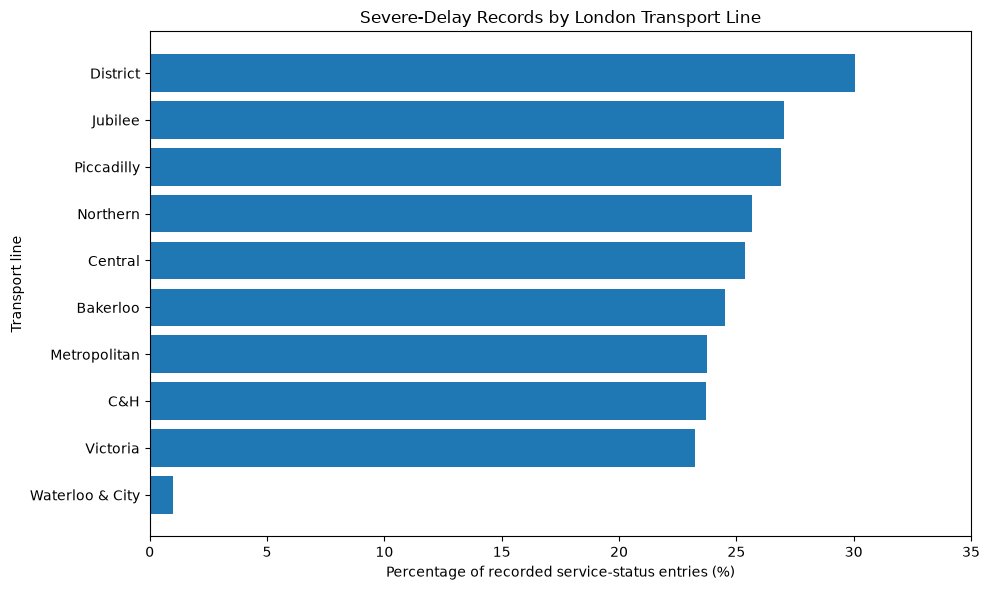

In [106]:
import matplotlib.pyplot as plt

chart_data = severe_delay_percentages.sort_values(
    "severe_delay_percentage",
    ascending=True
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    chart_data["Line"],
    chart_data["severe_delay_percentage"]
)

ax.set_title("Severe-Delay Records by London Transport Line")
ax.set_xlabel("Percentage of recorded service-status entries (%)")
ax.set_ylabel("Transport line")
ax.set_xlim(0, 35)

plt.tight_layout()
plt.show()

# Uses the results from SQL Query 3 stored in severe_delay_percentages.
# Sorts transport lines by severe-delay percentage.
# Creates a horizontal bar chart for easy comparison.
# Adds a title and labels to explain what the chart measures.
# Sets the horizontal axis from 0% to 35%.
# Displays the completed chart in the notebook.

In [107]:
from pathlib import Path

charts_folder = data_path.parent.parent / "outputs" / "charts"
charts_folder.mkdir(parents=True, exist_ok=True)

chart_1_path = charts_folder / "severe_delay_percentage_by_line.png"

fig.savefig(
    chart_1_path,
    dpi=300,
    bbox_inches="tight"
)

print("Chart saved to:", chart_1_path)
print("File exists:", chart_1_path.exists())

# Creates an outputs/charts folder inside the project if needed.
# Saves the existing Matplotlib figure as a PNG image.
# dpi=300 produces a high-resolution image suitable for reports.
# bbox_inches="tight" prevents chart labels from being cut off.
# Checks that the file was successfully saved.

Chart saved to: /Users/harirazannah/Desktop/london-transport-reliability/data/outputs/charts/severe_delay_percentage_by_line.png
File exists: True


### Chart 2: Severe-Delay Records by Hour

Visualise when severe-delay service-status intervals begin throughout the day, highlighting patterns around typical commuting hours.

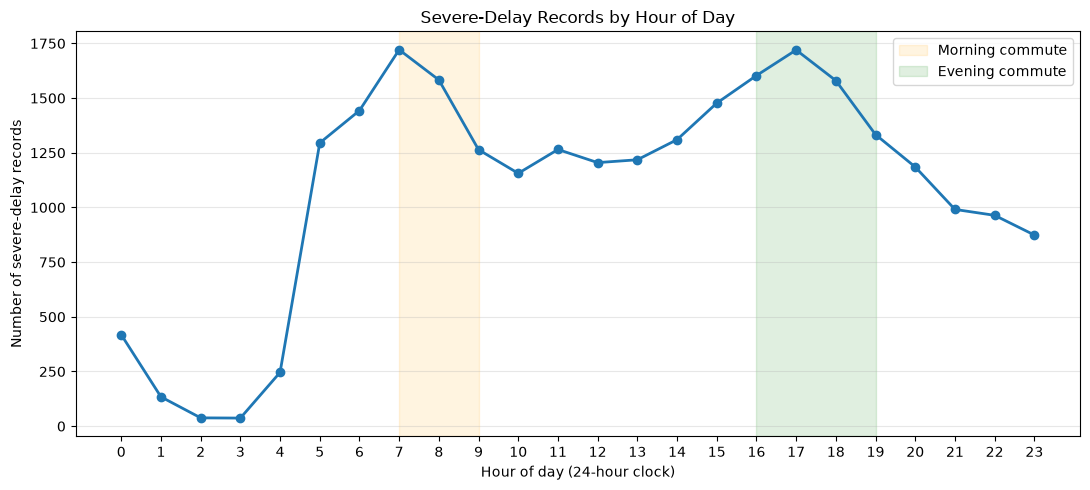

In [108]:
fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    hourly_delays["hour"],
    hourly_delays["severe_delay_records"],
    marker="o",
    linewidth=2
)

ax.axvspan(7, 9, alpha=0.12, color="orange", label="Morning commute")
ax.axvspan(16, 19, alpha=0.12, color="green", label="Evening commute")

ax.set_title("Severe-Delay Records by Hour of Day")
ax.set_xlabel("Hour of day (24-hour clock)")
ax.set_ylabel("Number of severe-delay records")
ax.set_xticks(range(0, 24))
ax.grid(axis="y", alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

# Uses hourly_delays, the DataFrame created by SQL Query 6.
# Plots the number of severe-delay records starting in each hour.
# Highlights typical morning and evening commuting periods.
# Displays all 24 hours on the horizontal axis.
# Counts recorded interval starts, not independent incidents or passenger risk.

In [109]:
chart_2_path = charts_folder / "severe_delay_records_by_hour.png"

fig.savefig(
    chart_2_path,
    dpi=300,
    bbox_inches="tight"
)

print("Chart saved to:", chart_2_path)
print("File exists:", chart_2_path.exists())

# Uses the charts_folder created when saving Chart 1.
# Saves the current hourly severe-delay chart as a PNG.
# Uses 300 DPI for a high-quality image suitable for GitHub and reports.
# Checks that the image was successfully saved.

Chart saved to: /Users/harirazannah/Desktop/london-transport-reliability/data/outputs/charts/severe_delay_records_by_hour.png
File exists: True


### Chart 3: Distrubution of Service-Status Records

Compare the frequency of different service-status categories across the cleaned TFL dataset.

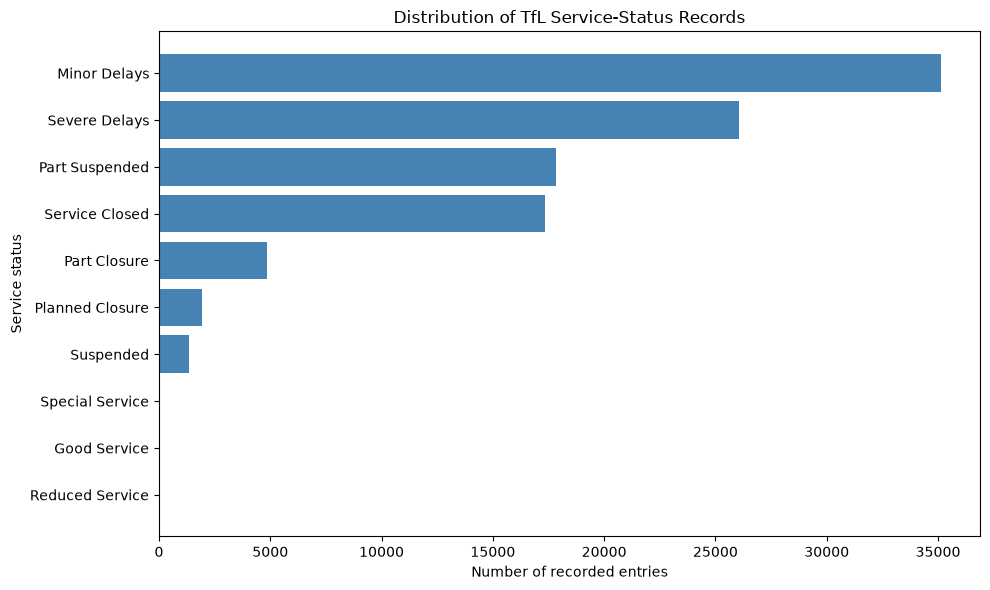

In [110]:
chart_data = status_summary.sort_values(
    "total_records",
    ascending=True
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    chart_data["Service Status"],
    chart_data["total_records"],
    color="steelblue"
)

ax.set_title("Distribution of TfL Service-Status Records")
ax.set_xlabel("Number of recorded entries")
ax.set_ylabel("Service status")

plt.tight_layout()
plt.show()

# Uses status_summary, the DataFrame created by SQL Query 4.
# Sorts statuses so the most frequent category appears at the top.
# Creates a horizontal bar chart comparing record counts.
# Labels the chart to show that these are recorded entries.
# Does not interpret record counts as independent disruption incidents.

In [111]:
chart_3_path = charts_folder / "service_status_distribution.png"

fig.savefig(
    chart_3_path,
    dpi=300,
    bbox_inches="tight"
)

print("Chart saved to:", chart_3_path)
print("File exists:", chart_3_path.exists())

# Saves the service-status distribution chart as a PNG.
# Checks that the file was saved successfully.

Chart saved to: /Users/harirazannah/Desktop/london-transport-reliability/data/outputs/charts/service_status_distribution.png
File exists: True


In [112]:
from pathlib import Path

project_folder = Path.cwd().resolve().parent

data_path = (
    project_folder
    / "data"
    / "raw"
    / "trains-service-status-messages.csv"
)

print("Project folder:", project_folder)
print("Dataset exists:", data_path.exists())

# Assumes the notebook is running from the project's notebooks folder.
# Moves up one folder to locate the project root.
# Builds the dataset path without using a personal Desktop location.
# Checks whether the dataset can be found.

Project folder: /Users/harirazannah/Desktop/london-transport-reliability
Dataset exists: True


In [113]:
processed_path = project_folder / "data" / "processed" / "tfl_service_status_cleaned.csv"

database_path = project_folder / "data" / "tfl_reliability.db"

print("Processed CSV exists:", processed_path.exists())
print("SQLite database exists:", database_path.exists())

# Builds both paths relative to the project folder.
# Checks whether the cleaned CSV is in data/processed.
# Checks whether the SQLite database is in the data folder.
# We are only checking files, not modifying or deleting anything.

Processed CSV exists: True
SQLite database exists: True


In [114]:
import sqlite3
import pandas as pd

with sqlite3.connect(database_path) as connection:
    database_check = pd.read_sql_query(
        "SELECT COUNT(*) AS total_records FROM service_status;",
        connection
    )

display(database_check)

# Connects to the SQLite database using the project-relative path.
# Counts the records in the service_status table.
# Confirms that the database can be opened and queried successfully.
# The expected result is 104,600 records.

,total_records
0,104600


In [115]:
gitignore_path = project_folder / ".gitignore"

gitignore_content = """# Python cache
__pycache__/
*.pyc

# Jupyter checkpoints
.ipynb_checkpoints/

# macOS files
.DS_Store

# Local environments
.venv/
venv/

# Local SQLite database
*.db
"""

gitignore_path.write_text(gitignore_content, encoding="utf-8")

print(".gitignore created:", gitignore_path.exists())
print(gitignore_path.read_text(encoding="utf-8"))

# Creates a .gitignore file in the project root.
# Excludes temporary Python, Jupyter and macOS files.
# Excludes local virtual environments and SQLite databases.
# Keeps the notebook, SQL scripts, charts and CSV files eligible for GitHub.


.gitignore created: True
# Python cache
__pycache__/
*.pyc

# Jupyter checkpoints
.ipynb_checkpoints/

# macOS files
.DS_Store

# Local environments
.venv/
venv/

# Local SQLite database
*.db



In [116]:
from pathlib import Path

print("PROJECT FILES\n")

for file_path in sorted(project_folder.rglob("*")):
    if file_path.is_file():
        relative_path = file_path.relative_to(project_folder)
        size_mb = file_path.stat().st_size / (1024 * 1024)

        if ".ipynb_checkpoints" not in file_path.parts:
            print(f"{relative_path} — {size_mb:.2f} MB")

# Lists files inside the London Transport Reliability project.
# Displays paths relative to the main project folder.
# Shows file sizes to identify anything unusually large.
# Skips Jupyter checkpoint files.
# Does not change or delete any files.

PROJECT FILES

.gitignore — 0.00 MB
.venv/bin/Activate.ps1 — 0.01 MB
.venv/bin/activate — 0.00 MB
.venv/bin/activate.csh — 0.00 MB
.venv/bin/activate.fish — 0.00 MB
.venv/bin/debugpy — 0.00 MB
.venv/bin/debugpy-adapter — 0.00 MB
.venv/bin/f2py — 0.00 MB
.venv/bin/fonttools — 0.00 MB
.venv/bin/ipython — 0.00 MB
.venv/bin/ipython3 — 0.00 MB
.venv/bin/jupyter — 0.00 MB
.venv/bin/jupyter-kernel — 0.00 MB
.venv/bin/jupyter-kernelspec — 0.00 MB
.venv/bin/jupyter-migrate — 0.00 MB
.venv/bin/jupyter-run — 0.00 MB
.venv/bin/jupyter-troubleshoot — 0.00 MB
.venv/bin/numpy-config — 0.00 MB
.venv/bin/pip — 0.00 MB
.venv/bin/pip3 — 0.00 MB
.venv/bin/pip3.12 — 0.00 MB
.venv/bin/pyftmerge — 0.00 MB
.venv/bin/pyftsubset — 0.00 MB
.venv/bin/pygmentize — 0.00 MB
.venv/bin/python — 6.46 MB
.venv/bin/python3 — 6.46 MB
.venv/bin/python3.12 — 6.46 MB
.venv/bin/ttx — 0.00 MB
.venv/lib/python3.12/site-packages/IPython/__init__.py — 0.01 MB
.venv/lib/python3.12/site-packages/IPython/__main__.py — 0.00 MB
.venv/

In [117]:
important_files = [
    "README.md",
    "readme.md",
    "requirements.txt",
    "sql/analysis.sql",
    "notebooks/01-data-exploration.ipynb",
    "data/raw/trains-service-status-messages.csv",
    "data/processed/tfl_service_status_cleaned.csv",
]

for filename in important_files:
    file_path = project_folder / filename

    if file_path.exists():
        print(f"{filename}: {file_path.stat().st_size:,} bytes")
    else:
        print(f"{filename}: Not found")

# Checks only the files needed for the GitHub portfolio.
# Avoids listing thousands of files inside .venv.
# Uses exact byte sizes so small files do not appear empty.
# Does not modify or delete any files.

README.md: 3,371 bytes
readme.md: 3,371 bytes
requirements.txt: 26 bytes
sql/analysis.sql: 2,011 bytes
notebooks/01-data-exploration.ipynb: 2,087,831 bytes
data/raw/trains-service-status-messages.csv: 26,280,615 bytes
data/processed/tfl_service_status_cleaned.csv: 24,242,563 bytes


In [118]:
for cell_number in personal_path_cells:
    cell = notebook_data["cells"][cell_number - 1]
    source = "".join(cell.get("source", []))

    print(f"\n{'=' * 45}")
    print(f"CELL {cell_number} — {cell['cell_type']}")
    print(f"{'=' * 45}")
    print(source[:1500])

# Inspects only cells 3, 97, 98 and 105.
# Shows whether each cell contains Python code or Markdown.
# Displays up to 1,500 characters per cell to keep the output manageable.
# Does not execute or change any notebook cells.


CELL 3 — code
from pathlib import Path

data_path = (
    Path.home()
    / "Desktop"
    / "london-transport-reliability"
    / "data"
    / "raw"
    / "trains-service-status-messages.csv"
)

print("CSV exists:", data_path.exists())

CELL 97 — code
from pathlib import Path
import shutil

project_folder = Path.home() / "Desktop" / "london-transport-reliability"

notebooks_folder = project_folder / "notebooks"
sql_folder = project_folder / "sql"
final_charts_folder = project_folder / "outputs" / "charts"

for folder in [notebooks_folder, sql_folder, final_charts_folder]:
    folder.mkdir(parents=True, exist_ok=True)

for chart_file in charts_folder.glob("*.png"):
    shutil.copy2(chart_file, final_charts_folder / chart_file.name)

print("Project folders created.")
print("Charts in final location:")

for chart_file in sorted(final_charts_folder.glob("*.png")):
    print("-", chart_file.name)

# Creates folders for the notebook, SQL queries and final charts.
# Copies the three PNG files